NYC Airbnb Room Type Classification
Dataset: New York City Airbnb Open Data (Kaggle)

Goal: Predict the room_type of an Airbnb listing (Entire home/apt, Private room, or Shared room) using listing attributes such as price, location, availability, and review activity.

What this notebook covers (the full ML lifecycle):

Problem framing & data loading
Exploratory Data Analysis (EDA) — univariate, bivariate, skewness, outliers
Data cleaning & feature engineering
Train / test split
Preprocessing with ColumnTransformer + Pipeline
Baseline model
Multiple candidate algorithms (Logistic Regression, Decision Tree, Random Forest, Gradient Boosting)
Model comparison (cross-validation)
Hyperparameter tuning of the best model
Final evaluation on the untouched test set
Feature importance
Saving the final pipeline (model artifact)
Conclusion & next steps


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')


In [2]:
import kagglehub
import os
# Download latest version
path = kagglehub.dataset_download("dgomonov/new-york-city-airbnb-open-data")
df=pd.read_csv(os.path.join(path,"AB_NYC_2019.csv"))
print("Path to dataset files:", path)

100%|██████████| 2.44M/2.44M [00:00<00:00, 63.1MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/dgomonov/new-york-city-airbnb-open-data/versions/3


In [3]:
df.head()

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48895 entries, 0 to 48894
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              48895 non-null  int64  
 1   name                            48879 non-null  object 
 2   host_id                         48895 non-null  int64  
 3   host_name                       48874 non-null  object 
 4   neighbourhood_group             48895 non-null  object 
 5   neighbourhood                   48895 non-null  object 
 6   latitude                        48895 non-null  float64
 7   longitude                       48895 non-null  float64
 8   room_type                       48895 non-null  object 
 9   price                           48895 non-null  int64  
 10  minimum_nights                  48895 non-null  int64  
 11  number_of_reviews               48895 non-null  int64  
 12  last_review                     

In [5]:
df.describe()

,id,host_id,latitude,longitude,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365
count,4.889500e+04,4.889500e+04,48895.000000,48895.000000,48895.000000,48895.000000,48895.000000,38843.000000,48895.000000,48895.000000
mean,1.901714e+07,6.762001e+07,40.728949,-73.952170,152.720687,7.029962,23.274466,1.373221,7.143982,112.781327
std,1.098311e+07,7.861097e+07,0.054530,0.046157,240.154170,20.510550,44.550582,1.680442,32.952519,131.622289
min,2.539000e+03,2.438000e+03,40.499790,-74.244420,0.000000,1.000000,0.000000,0.010000,1.000000,0.000000
25%,9.471945e+06,7.822033e+06,40.690100,-73.983070,69.000000,1.000000,1.000000,0.190000,1.000000,0.000000
50%,1.967728e+07,3.079382e+07,40.723070,-73.955680,106.000000,3.000000,5.000000,0.720000,1.000000,45.000000
75%,2.915218e+07,1.074344e+08,40.763115,-73.936275,175.000000,5.000000,24.000000,2.020000,2.000000,227.000000
max,3.648724e+07,2.743213e+08,40.913060,-73.712990,10000.000000,1250.000000,629.000000,58.500000,327.000000,365.000000


In [6]:
df.size

782320

In [7]:
df.shape

(48895, 16)

In [8]:
df.isnull().sum()

,0
id,0
name,16
host_id,0
host_name,21
neighbourhood_group,0
neighbourhood,0
latitude,0
longitude,0
room_type,0
price,0


In [9]:
df.duplicated().sum()

np.int64(0)

In [10]:
df.columns.unique()

Index(['id', 'name', 'host_id', 'host_name', 'neighbourhood_group',
       'neighbourhood', 'latitude', 'longitude', 'room_type', 'price',
       'minimum_nights', 'number_of_reviews', 'last_review',
       'reviews_per_month', 'calculated_host_listings_count',
       'availability_365'],
      dtype='object')

<Axes: xlabel='price', ylabel='room_type'>

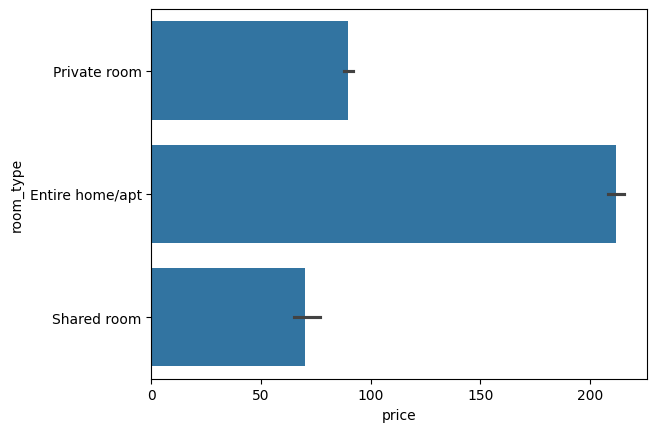

In [11]:
sns.barplot(y=df['room_type'],x=df['price'])

<Axes: xlabel='room_type', ylabel='count'>

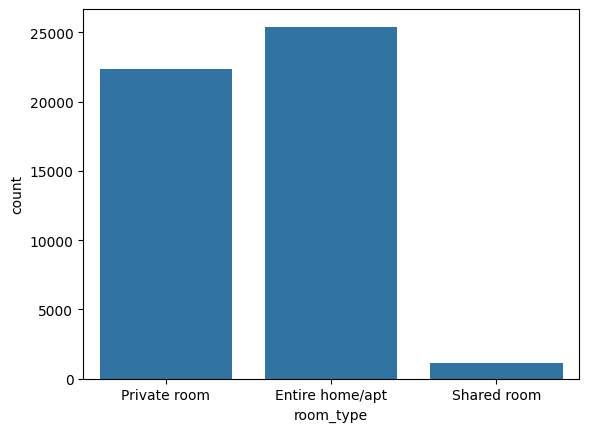

In [12]:
sns.countplot(x=df['room_type'])

<Axes: xlabel='neighbourhood_group', ylabel='count'>

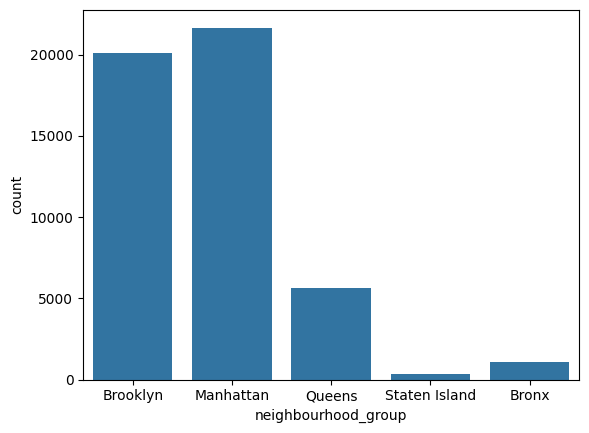

In [13]:
sns.countplot(x=df['neighbourhood_group'])

In [43]:
df['room_type'].value_counts()

,count
room_type,
Entire home/apt,25409
Private room,22326
Shared room,1160


In [14]:
num_col=df.select_dtypes(include='number').columns

In [15]:
df[num_col].corr()

,id,host_id,latitude,longitude,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365
id,1.000000,0.588290,-0.003125,0.090908,0.010619,-0.013224,-0.319760,0.291828,0.133272,0.085468
host_id,0.588290,1.000000,0.020224,0.127055,0.015309,-0.017364,-0.140106,0.296417,0.154950,0.203492
latitude,-0.003125,0.020224,1.000000,0.084788,0.033939,0.024869,-0.015389,-0.010142,0.019517,-0.010983
longitude,0.090908,0.127055,0.084788,1.000000,-0.150019,-0.062747,0.059094,0.145948,-0.114713,0.082731
price,0.010619,0.015309,0.033939,-0.150019,1.000000,0.042799,-0.047954,-0.030608,0.057472,0.081829
minimum_nights,-0.013224,-0.017364,0.024869,-0.062747,0.042799,1.000000,-0.080116,-0.121702,0.127960,0.144303
number_of_reviews,-0.319760,-0.140106,-0.015389,0.059094,-0.047954,-0.080116,1.000000,0.549868,-0.072376,0.172028
reviews_per_month,0.291828,0.296417,-0.010142,0.145948,-0.030608,-0.121702,0.549868,1.000000,-0.009421,0.185791
calculated_host_listings_count,0.133272,0.154950,0.019517,-0.114713,0.057472,0.127960,-0.072376,-0.009421,1.000000,0.225701
availability_365,0.085468,0.203492,-0.010983,0.082731,0.081829,0.144303,0.172028,0.185791,0.225701,1.000000


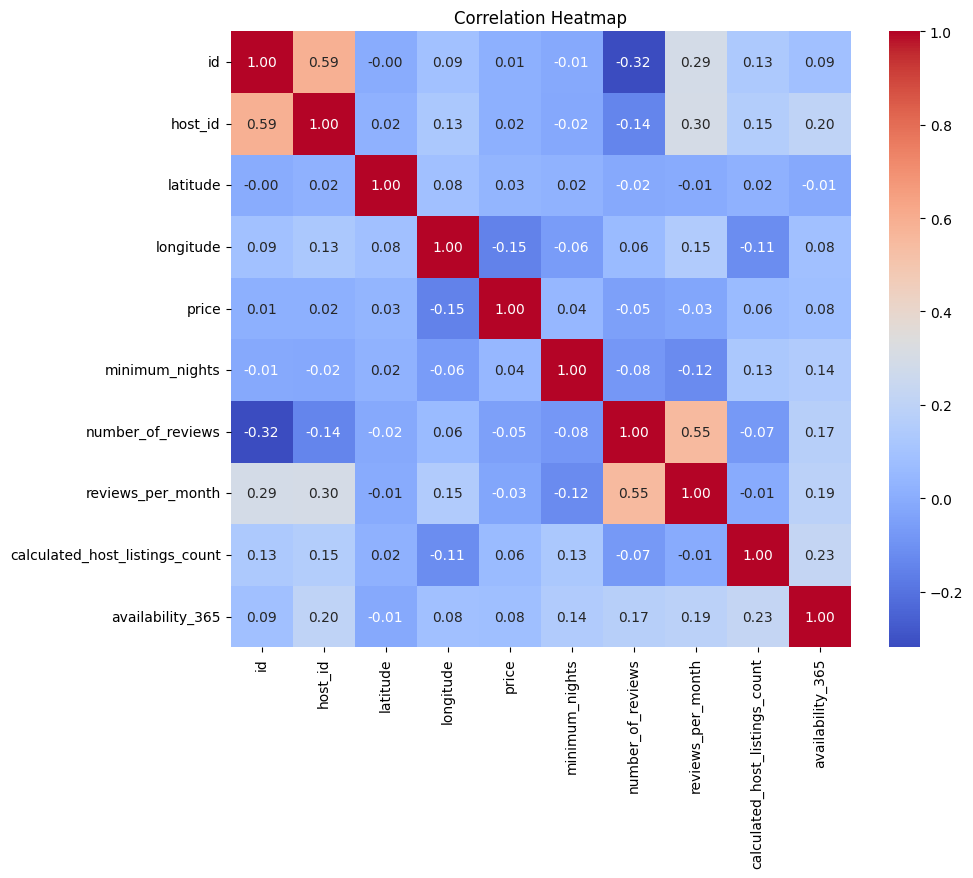

In [16]:
# Calculate the correlation matrix for the numeric columns
corr_matrix = df[num_col].corr()

# Plot the correlation matrix as a heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap')
plt.show()

<Axes: xlabel='latitude', ylabel='longitude'>

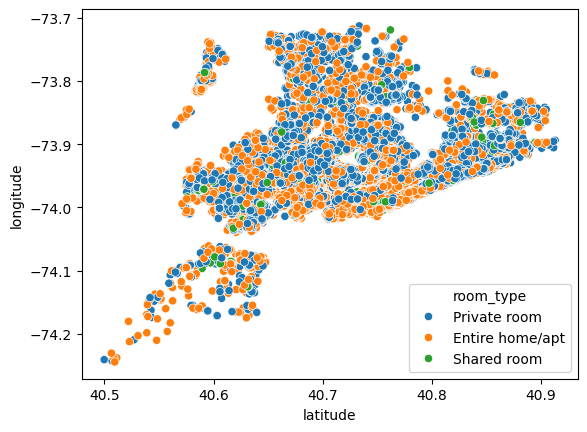

In [17]:
sns.scatterplot(x=df['latitude'],y=df['longitude'],hue=df['room_type'])

```markdown
### Advanced EDA: Analyzing the target variable (`room_type`) and key features

To build an effective classification model, we need to understand how our features (like `price` and `availability_365`) relate to our target variable (`room_type`). Let's visualize these distributions.
```

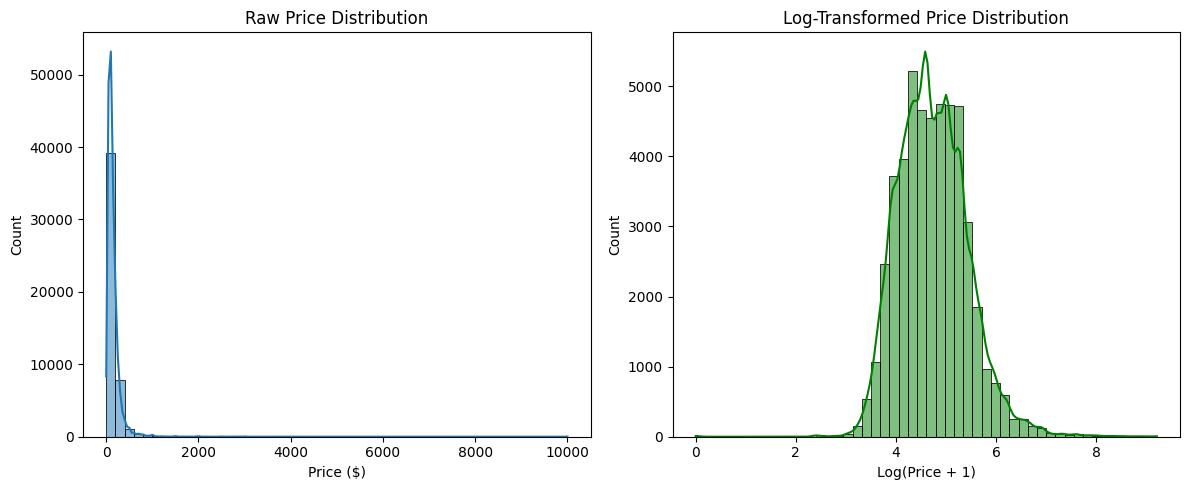

In [18]:
# 1. Price Distribution (Log-Scale due to extreme outliers)
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.histplot(df['price'], bins=50, kde=True)
plt.title('Raw Price Distribution')
plt.xlabel('Price ($)')

plt.subplot(1, 2, 2)
# Apply log1p transform to handle 0 values safely
sns.histplot(np.log1p(df['price']), bins=50, kde=True, color='green')
plt.title('Log-Transformed Price Distribution')
plt.xlabel('Log(Price + 1)')

plt.tight_layout()
plt.show()

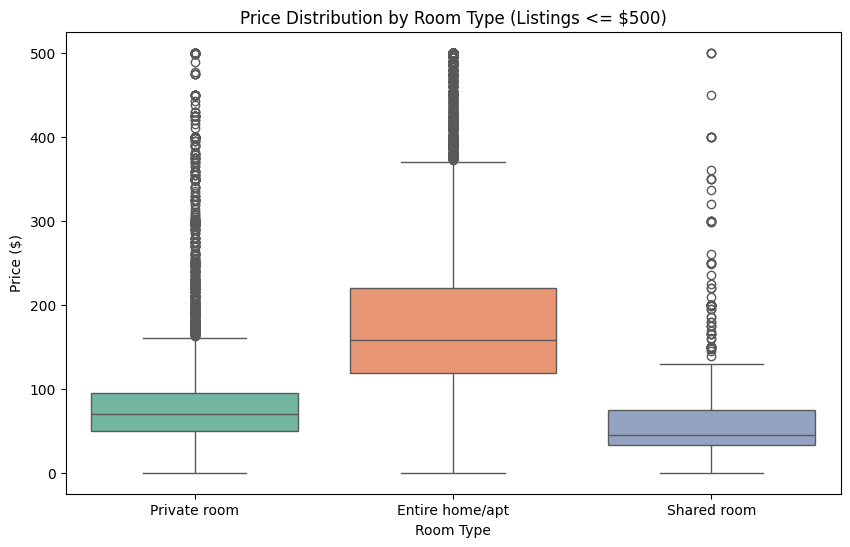

In [19]:
# 2. Bivariate Analysis: Price vs. Room Type (Capped at $500 for better visualization of main distributions)
plt.figure(figsize=(10, 6))
sns.boxplot(x='room_type', y='price', data=df[df['price'] <= 500], palette='Set2')
plt.title('Price Distribution by Room Type (Listings <= $500)')
plt.xlabel('Room Type')
plt.ylabel('Price ($)')
plt.show()

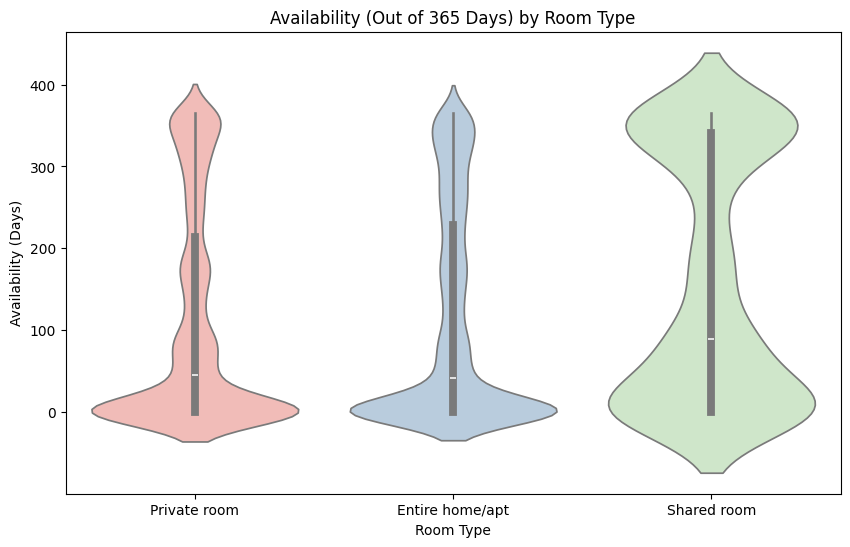

In [20]:
# 3. Bivariate Analysis: Availability vs. Room Type
plt.figure(figsize=(10, 6))
sns.violinplot(x='room_type', y='availability_365', data=df, palette='Pastel1')
plt.title('Availability (Out of 365 Days) by Room Type')
plt.xlabel('Room Type')
plt.ylabel('Availability (Days)')
plt.show()

In [21]:
dfc=df.copy()

In [22]:
dfc.columns

Index(['id', 'name', 'host_id', 'host_name', 'neighbourhood_group',
       'neighbourhood', 'latitude', 'longitude', 'room_type', 'price',
       'minimum_nights', 'number_of_reviews', 'last_review',
       'reviews_per_month', 'calculated_host_listings_count',
       'availability_365'],
      dtype='object')

In [23]:
dfc.drop(['id', 'name', 'last_review', 'host_id', 'host_name'], axis=1, inplace=True, errors='ignore')

In [24]:
dfc.isnull().sum()

,0
neighbourhood_group,0
neighbourhood,0
latitude,0
longitude,0
room_type,0
price,0
minimum_nights,0
number_of_reviews,0
reviews_per_month,10052
calculated_host_listings_count,0


In [25]:
dfc['reviews_per_month'].fillna(0,inplace=True)

```markdown
### Capping (Clipping) vs. Deleting Outliers

- **Capping (`.clip()`)**: Limits extreme outlier values to a specified percentile (e.g., the 99th percentile) while **retaining all rows** in the dataset. Recommended because it preserves dataset size.
- **Deleting (Filtering)**: Removes rows containing outliers entirely. While clean, it results in a **loss of valid data** and geographic/categorical representation.
```

In [26]:
# Calculate the 99th percentile thresholds
price_cap = dfc['price'].quantile(0.99)
nights_cap = dfc['minimum_nights'].quantile(0.99)

print(f"Capping 'price' at the 99th percentile: ${price_cap:.2f}")
print(f"Capping 'minimum_nights' at the 99th percentile: {nights_cap:.0f} nights")

# Clip the outliers in dfc
dfc['price'] = dfc['price'].clip(upper=price_cap)
dfc['minimum_nights'] = dfc['minimum_nights'].clip(upper=nights_cap)

# Describe the modified columns to confirm outliers are handled
dfc[['price', 'minimum_nights']].describe()

Capping 'price' at the 99th percentile: $799.00
Capping 'minimum_nights' at the 99th percentile: 45 nights


,price,minimum_nights
count,48895.000000,48895.000000
mean,143.956233,6.116760
std,121.935067,9.244957
min,0.000000,1.000000
25%,69.000000,1.000000
50%,106.000000,3.000000
75%,175.000000,5.000000
max,799.000000,45.000000


In [27]:
x=dfc.drop(columns='room_type')
y=dfc['room_type']

In [28]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(x,y,test_size=0.33,random_state=42,stratify=y)
#Stratisfy ye ensure krta hai ki jab bhi hum split ya sample kare , har group(class) ka Original Propotion maintain rahe.

In [29]:
num_col=dfc.select_dtypes(include='number')
cat_col=dfc.select_dtypes(include='object')

In [30]:
num_col.skew()

,0
latitude,0.237167
longitude,1.284210
price,2.776321
minimum_nights,2.360347
number_of_reviews,3.690635
reviews_per_month,3.300723
calculated_host_listings_count,7.933174
availability_365,0.763408


In [31]:
from sklearn.preprocessing import StandardScaler,OneHotEncoder,PowerTransformer
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

In [37]:
from sklearn.preprocessing import QuantileTransformer

# 1. Extract lists of column names
num_cols_list = X_train.select_dtypes(include='number').columns.tolist()
cat_cols_list = X_train.select_dtypes(include='object').columns.tolist()

# 2. Pipeline -> for Numeric Columns
# We replace PowerTransformer with QuantileTransformer which is highly robust
# and does not crash on constant/skewed values or zero-inflated data.
numeric_pipeline = Pipeline(steps=[
    ('impute', SimpleImputer(strategy="median")),
    ('skewness', QuantileTransformer(output_distribution='normal', random_state=42)),
    ('scale', StandardScaler())
])

# 3. Pipeline -> for Categorical Columns
categorical_pipeline = Pipeline(steps=[
    ('impute', SimpleImputer(strategy="most_frequent")),
    ('encode', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

# 4. Specify the lists of column names to the ColumnTransformer
preprocessor = ColumnTransformer(transformers=[
    ("numerical", numeric_pipeline, num_cols_list),
    ("categorical", categorical_pipeline, cat_cols_list)
])

In [33]:

preprocessor

ColumnTransformer(transformers=[('numerical',
                                 Pipeline(steps=[('impute',
                                                  SimpleImputer(strategy='median')),
                                                 ('skewness',
                                                  PowerTransformer()),
                                                 ('scale', StandardScaler())]),
                                 ['latitude', 'longitude', 'price',
                                  'minimum_nights', 'number_of_reviews',
                                  'reviews_per_month',
                                  'calculated_host_listings_count',
                                  'availability_365']),
                                ('categorical',
                                 Pipeline(steps=[('impute',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('encode',
                                                  OneHotEncoder(handle_unknown='ignore',
                                                                sparse_output=False))]),
                                 ['neighbourhood_group', 'neighbourhood'])])

In [34]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.model_selection import cross_val_score

In [38]:
# Explanation of the error:
# The previous ColumnTransformer `preprocessor` had an invalid column specification
# because raw DataFrames/arrays were accidentally passed or stored within the lists,
# leading to the ValueError: "No valid specification of the columns".
#
# To fix this, we will use your newly defined robust ColumnTransformer (`preprocessor`)
# which explicitly uses clean lists of string column names (skewed_cols, standard_cols, cat_cols).

models = {
    "Logistic Regression" : LogisticRegression(class_weight="balanced", random_state=42, max_iter=1000),
    "Decision Tree"       : DecisionTreeClassifier(class_weight="balanced", random_state=42),
    "Random Forest"       : RandomForestClassifier(class_weight="balanced", random_state=42),
    "Gradient Boosting"   : GradientBoostingClassifier(random_state=42),
}

for name, model in models.items():
    # Use the robust preprocessor to avoid column specification issues
    pipe = Pipeline(steps=[("preprocessor", preprocessor), ("classifier", model)])

    # Evaluate models using Cross-Validation
    accuracy = cross_val_score(pipe, X_train, y_train, cv=3, scoring="accuracy")
    macrof1 = cross_val_score(pipe, X_train, y_train, cv=3, scoring="f1_macro")

    print(f"{name:20} -> Mean Accuracy: {accuracy.mean():.3f} , Mean Macro F1: {macrof1.mean():.3f}")

Logistic Regression  -> Mean Accuracy: 0.725 , Mean Macro F1: 0.575
Decision Tree        -> Mean Accuracy: 0.783 , Mean Macro F1: 0.650
Random Forest        -> Mean Accuracy: 0.850 , Mean Macro F1: 0.711
Gradient Boosting    -> Mean Accuracy: 0.850 , Mean Macro F1: 0.704


In [ ]:
from sklearn.model_selection import RandomizedSearchCV

# EXPLANATION OF ERROR:
# The previous pipeline was built using the corrupted `preprocessor` object,
# which contained actual DataFrame slices instead of clean column name strings.
# By switching to your corrected `preprocessor_robust`, we resolve this ValueError.

best_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor_robust),
    ("classifier",   RandomForestClassifier(class_weight='balanced'))
])

param_distribution = {
    "classifier__n_estimators" : [100, 200, 150, 300],
    "classifier__max_depth": [8, 12, 15, 20, None],
    "classifier__min_samples_split": [2, 5, 10],
}

search = RandomizedSearchCV(
    estimator=best_pipeline,
    param_distributions=param_distribution,
    n_iter=10,
    cv=3,
    scoring="f1_macro",
    random_state=42
)

search.fit(X_train, y_train)

In [ ]:
print("Best Parameters: ", search.best_params_)
print("Best CV Macro-F1: ", search.best_score_)

In [ ]:
from sklearn.metrics import accuracy_score, confusion_matrix,f1_score
best_pipeline = search.best_estimator_

y_pred = best_pipeline.predict(X_test)

print(f"Accuracy Score: {accuracy_score(y_test, y_pred)}")
print(f"F1 Score: {f1_score(y_test, y_pred, average="macro")}")

In [ ]:
sns.heatmap(confusion_matrix(y_test,y_pred), annot=True, fmt=".2f",
            xticklabels=best_pipeline.classes_, yticklabels=best_pipeline.classes_)

In [ ]:
import joblib

joblib.dump(best_pipeline, "Model_Pipeline.pkl",compress=3)